# Tome S2, Chapter 5: Conics (Python companion)

Exercises first, solutions at the end. We fit conics through five points, test Pascal's theorem in exact arithmetic, watch the cross-ratio of four points on a conic stay put, check the harmonic property of the polar, and draw Poncelet polygons, measuring the hidden rotation of the porism and testing the closing conditions of Euler and Fuss. We use `fractions`, `numpy`, `sympy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
from fractions import Fraction as Fr
from math import gcd
import math, random
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
random.seed(5)
def cross(p, q):
    return (p[1] * q[2] - p[2] * q[1], p[2] * q[0] - p[0] * q[2], p[0] * q[1] - p[1] * q[0])
def det3(p, q, r):
    return sum(a * b for a, b in zip(cross(p, q), r))

## Exercises

**P5.1 (★) Five points.** Write a function returning the conic through five points (the null space of a $5\times6$ matrix). Check Exercise 5.1, and check on random points that the null space is one-dimensional and the conic nondegenerate (Theorem 5.3).

**P5.2 (★) Pascal, exactly.** Take six random rational points of the conic $y^2=xz$ (Theorem 5.4), move them by a random rational projective map, and check Theorem 5.8 with exact fractions for $1000$ hexagons. Then check Brianchon (Exercise 5.7) on the tangent lines.

**P5.3 (★) The cross-ratio seen from the conic.** On the ellipse $x^2/4+y^2=1$ fix four points and compute the cross-ratio of the four lines from a fifth point $P$ (cut them by a line), for $20$ positions of $P$ (Theorem 5.6).

**P5.4 (★) Polars.** For a random point $P$ outside the ellipse and random lines through $P$, check that the polar cuts each secant at the harmonic conjugate of $P$ (Proposition 5.10). Carry out the straightedge construction of Exercise 5.9 numerically and check that the lines you get are tangent.

**P5.5 (★★) Poncelet's porism.** Implement the map $T$ of Theorem 5.11. For $R=1$ and several $r,d$, compute the rotation number $\alpha/2\pi$ from the invariant measure $\int ds/t$ and compare it with the average advance of $T$ along an orbit. Check that the zigzag closes after $3$ steps when $d^2=R^2-2Rr$ (Exercise 5.11) and after $4$ steps under Fuss' condition, for many starting points. Plot an orbit that does not close.

**P5.6 (★) Pythagorean triples.** List the primitive Pythagorean triples with hypotenuse at most $100$ using the rational parametrisation of the circle (Exercise 5.4), and check the list against a brute-force search.

## Solutions

### P5.1
**How to find it.** Each point $(x,y)$ gives a row $(x^2,xy,y^2,x,y,1)$; the conic is a vector in the null space. Exact arithmetic with `sympy` makes the rank exact.

In [2]:
def conic_through(pts):
    M = sp.Matrix([[x * x, x * y, y * y, x, y, 1] for x, y in pts])
    ns = M.nullspace()
    return ns
def conic_matrix(v):
    a, b, c, d, e, f = v
    return sp.Matrix([[a, b / 2, d / 2], [b / 2, c, e / 2], [d / 2, e / 2, f]])
x, y = sp.symbols("x y")
ns = conic_through([(0, 0), (1, 0), (0, 1), (1, 2), (2, 1)])
v = ns[0] / ns[0][0]
print("Exercise:", sp.expand(sum(c * m for c, m in zip(v, [x**2, x*y, y**2, x, y, 1]))), "= 0")
from itertools import combinations
dims, nondeg, skipped = [], 0, 0
while len(dims) < 200:
    pts = [(sp.Rational(random.randint(-20, 20), random.randint(1, 5)), sp.Rational(random.randint(-20, 20), random.randint(1, 5))) for _ in range(5)]
    if any(det3((*p, 1), (*q, 1), (*r, 1)) == 0 for p, q, r in combinations(pts, 3)):
        skipped += 1; continue      # three points on a line: not covered by the theorem
    ns = conic_through(pts)
    dims.append(len(ns)); nondeg += conic_matrix(ns[0]).det() != 0
print("null space dimensions:", set(dims), "| nondegenerate:", nondeg, "of 200 | skipped (three collinear):", skipped)

Exercise: x**2 - x*y - x + y**2 - y = 0


null space dimensions: {1} | nondegenerate: 200 of 200 | skipped (three collinear): 2


The exercise conic is $x^2-xy+y^2-x-y=0$. Random points with no three on a line always give a one-dimensional null space and a nondegenerate conic. Small random rationals do occasionally put three points on a line; then the theorem does not apply. Every conic through the five points contains the line through the three (it meets that line three times), so it is degenerate; and if four of the points are on a line, the conic is not even unique, since that line together with any line through the fifth point will do.

### P5.2
**How to find it.** Points $[1:t:t^2]$ are on $y^2=xz$; a random invertible integer matrix moves them to a random conic. Join and meet with cross products. For Brianchon, the tangent at $[p]$ is $[Ap]$, so the tangent lines of the image conic are the images of the tangent lines of $y^2=xz$ under the inverse transpose.

In [3]:
A0 = [[0, 0, Fr(-1, 2)], [0, 1, 0], [Fr(-1, 2), 0, 0]]    # matrix of y^2 - xz
def matvec(M, v): return tuple(sum(M[i][j] * v[j] for j in range(3)) for i in range(3))
def rand_matrix():
    while True:
        M = [[Fr(random.randint(-5, 5)) for _ in range(3)] for _ in range(3)]
        if det3(*[tuple(r) for r in M]) != 0: return M
bad_p = bad_b = 0
for _ in range(1000):
    ts = random.sample(range(-40, 40), 6)
    M = rand_matrix()
    pts = [matvec(M, (1, Fr(t), Fr(t) ** 2)) for t in ts]
    A, B, Cc, D, E, F = pts
    X = cross(cross(A, B), cross(D, E)); Y = cross(cross(B, Cc), cross(E, F)); Z = cross(cross(Cc, D), cross(F, A))
    bad_p += det3(X, Y, Z) != 0
    # tangent lines of y^2 = xz at [1:t:t^2] are A0 (1,t,t^2); map lines by the inverse transpose of M
    Mi = sp.Matrix(M).inv().T
    tang = [tuple(Fr(str(c)) for c in Mi * sp.Matrix(matvec(A0, (1, Fr(t), Fr(t) ** 2)))) for t in ts]
    a, b, c, d, e, f = tang
    v1, v2, v3 = (cross(cross(a, b), cross(d, e)), cross(cross(b, c), cross(e, f)), cross(cross(c, d), cross(f, a)))
    bad_b += det3(v1, v2, v3) != 0
print("Pascal failures:", bad_p, "| Brianchon failures:", bad_b)

Pascal failures: 0 | Brianchon failures: 0


No failures: the three Pascal points are always exactly collinear, and the three main diagonals of the circumscribed hexagons always pass through one point. (For Brianchon, $v_1,v_2,v_3$ are the diagonals as lines, and three lines are concurrent exactly when their coordinate vectors are dependent.)

### P5.3
**How to find it.** Parametrise the ellipse by angle, cut the four lines from $P$ with a fixed line not through $P$, and use the cross-ratio formula on the positions along that line.

In [4]:
E = lambda th: np.array([2 * math.cos(th), math.sin(th), 1.0])
A, B, Cc, D = [E(t) for t in (0.3, 1.4, 2.6, 4.0)]
def cr4(a, b, c, d): return (c - a) * (d - b) / ((c - b) * (d - a))
vals = []
for th in np.linspace(4.3, 6.2, 20):
    P = E(th)
    m = np.array([1.0, 0.3, -6.0])          # the line x + 0.3 y = 6, far from the ellipse
    cuts = [np.cross(np.cross(P, Q), m) for Q in (A, B, Cc, D)]
    s = [c[1] / c[2] for c in cuts]        # y-coordinate along the cutting line
    vals.append(cr4(*s))
print(np.round(vals, 12))

[1.62037352 1.62037352 1.62037352 1.62037352 1.62037352 1.62037352
 1.62037352 1.62037352 1.62037352 1.62037352 1.62037352 1.62037352
 1.62037352 1.62037352 1.62037352 1.62037352 1.62037352 1.62037352
 1.62037352 1.62037352]


Twenty positions of $P$, one cross-ratio. (The cutting line $x+0.3y=6$ stays away from the ellipse, so it never passes through $P$, and the $y$-coordinate is an affine coordinate on it.)

### P5.4
**How to find it.** With $A=\mathrm{diag}(1/4,1,-1)$ the polar of $p$ is $Ap$. For a secant $p+s\,u$, solve the quadratic for $M,N$ and intersect with the polar for $Q$; then compute $(M,N;P,Q)$ in the parameter $s$.

In [5]:
Am = np.diag([0.25, 1.0, -1.0])
q = lambda v: v @ Am @ v
P = np.array([2.6, 1.7, 1.0])
pol = Am @ P
res = []
for ang in np.linspace(3.3, 4.0, 8):
    u = np.array([math.cos(ang), math.sin(ang), 0.0])
    a2, a1, a0 = q(u), 2 * (P @ Am @ u), q(P)
    disc = a1 * a1 - 4 * a2 * a0
    if disc <= 0: continue
    s1, s2 = (-a1 - math.sqrt(disc)) / (2 * a2), (-a1 + math.sqrt(disc)) / (2 * a2)
    sq = -(pol @ P) / (pol @ u)
    res.append(cr4(s1, s2, 0.0, sq))
print("cross-ratios (M,N;P,Q):", np.round(res, 12))
# the straightedge construction of the tangents
def secant_points(p, u):
    a2, a1, a0 = q(u), 2 * (p @ Am @ u), q(p)
    r = math.sqrt(a1 * a1 - 4 * a2 * a0)
    return [p + s * u for s in ((-a1 - r) / (2 * a2), (-a1 + r) / (2 * a2))]
M1, N1 = secant_points(P, np.array([-1.0, -0.5, 0.0]))
M2, N2 = secant_points(P, np.array([-1.0, -0.9, 0.0]))
Rr = np.cross(np.cross(M1, M2), np.cross(N1, N2)); S = np.cross(np.cross(M1, N2), np.cross(N1, M2))
line_RS = np.cross(Rr, S)
print("RS is the polar of P:", np.allclose(np.cross(line_RS, pol), 0, atol=1e-9 * np.linalg.norm(line_RS) * np.linalg.norm(pol)))
# points of contact: intersect the polar with the ellipse, then check tangency (the polar of T passes through P)
d = np.cross(pol, np.array([0.0, 0.0, 1.0])); p0 = np.cross(pol, np.array([1.0, 0.0, 0.0]))
for T in secant_points(p0 / p0[2], d):
    print("tangent check: q(T) =", round(q(T) / T[2] ** 2, 12), " P on polar of T:", round((Am @ T) @ P, 12))

cross-ratios (M,N;P,Q): [-1. -1. -1. -1. -1. -1. -1.]
RS is the polar of P: True
tangent check: q(T) = 0.0  P on polar of T: 0.0
tangent check: q(T) = -0.0  P on polar of T: 0.0


Every secant gives exactly $-1$. The line through $R$ and $S$ coincides with the polar $Ap$, and the two points where it meets the ellipse are points of contact: the lines from $P$ to them are the tangents.

### P5.5
**How to find it.** Use the formula of the figure script: rotate the direction from $x$ to the centre $c$ of $\omega$ by $\arcsin(r/|x-c|)$ and reflect to get the second point on $\Gamma$. The invariant measure is $\int d\theta/t(\theta)$ (with $R=1$, $ds=d\theta$); the rotation number is $\mu([x,T(x)])/\mu(\Gamma)$ for any $x$.

r=0.3, d=0.2000: measure gives 0.600440, orbit average 0.600454
r=0.36, d=0.5292: measure gives 0.666666, orbit average 0.666768
r=0.5, d=0.1000: measure gives 0.668544, orbit average 0.668538
Euler, triangles: worst gap after 3 steps 1.6280159398840505e-14
Fuss, quadrilaterals: d = 0.3273579370, worst gap after 4 steps 2.0244929030872094e-14


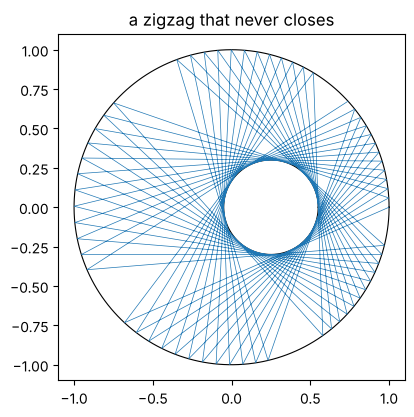

In [6]:
def make_T(r, d):
    c = np.array([d, 0.0])
    def T(x):
        v = c - x; L = np.linalg.norm(v); al = math.asin(r / L); u = v / L
        u = np.array([u[0] * math.cos(al) - u[1] * math.sin(al), u[0] * math.sin(al) + u[1] * math.cos(al)])
        return x - 2 * (x @ u) * u
    return T
ang = lambda x: math.atan2(x[1], x[0]) % (2 * math.pi)
def rotation_number(r, d, N=20000):
    th = np.linspace(0, 2 * math.pi, N, endpoint=False) + math.pi / N
    t = np.sqrt((np.cos(th) - d) ** 2 + np.sin(th) ** 2 - r * r)
    w = (2 * math.pi / N) / t                      # midpoint rule for mu
    T = make_T(r, d); x0 = np.array([1.0, 0.0]); a1 = ang(T(x0))
    return w[th < a1].sum() / w.sum()
for r, d in ((0.3, 0.2), (0.36, math.sqrt(1 - 0.72)), (0.5, 0.1)):
    T = make_T(r, d); x = np.array([math.cos(1.0), math.sin(1.0)]); tot = 0.0
    for _ in range(2000):
        y = T(x); tot += (ang(y) - ang(x)) % (2 * math.pi); x = y
    print(f"r={r}, d={d:.4f}: measure gives {rotation_number(r, d):.6f}, orbit average {tot / 2000 / (2 * math.pi):.6f}")
def max_gap(r, d, n, starts=50):
    T = make_T(r, d); worst = 0.0
    for th in np.linspace(0, 2 * math.pi, starts, endpoint=False):
        x = np.array([math.cos(th), math.sin(th)]); y = x
        for _ in range(n): y = T(y)
        worst = max(worst, np.linalg.norm(y - x))
    return worst
r = 0.3; d = math.sqrt(1 - 2 * r)
print("Euler, triangles: worst gap after 3 steps", max_gap(r, d, 3))
r = 0.6; f = lambda d: 1 / (1 - d) ** 2 + 1 / (1 + d) ** 2 - 1 / r ** 2
lo, hi = 0.0, 0.35
for _ in range(80):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if f(lo) * f(mid) > 0 else (lo, mid)
print(f"Fuss, quadrilaterals: d = {lo:.10f}, worst gap after 4 steps", max_gap(r, lo, 4))
T = make_T(0.3, 0.25); x = np.array([1.0, 0.0]); orbit = [x]
for _ in range(60): orbit.append(T(orbit[-1]))
orbit = np.array(orbit); tt = np.linspace(0, 2 * math.pi, 400)
plt.figure(figsize=(4.5, 4.5)); plt.plot(np.cos(tt), np.sin(tt), "k", lw=0.8); plt.plot(0.25 + 0.3 * np.cos(tt), 0.3 * np.sin(tt), "k", lw=0.8)
plt.plot(orbit[:, 0], orbit[:, 1], lw=0.5); plt.gca().set_aspect("equal"); plt.title("a zigzag that never closes"); plt.show()

The rotation number computed from the invariant measure agrees with the average advance along an orbit, as the proof of Theorem 5.11 predicts: in the coordinate given by $\mu$, $T$ is a rotation. Under Euler's condition every start closes after $3$ steps, and under Fuss' condition after $4$, up to rounding. A generic pair of circles gives an irrational rotation, whose zigzag fills the annulus between the circles densely.

### P5.6
**How to find it.** Coprime $m>n>0$ of opposite parity give the primitive triples $(m^2-n^2,2mn,m^2+n^2)$; brute force checks all $a<b<c\le100$.

In [7]:
para = sorted(tuple(sorted((m * m - n * n, 2 * m * n))) + (m * m + n * n,)
              for m in range(2, 11) for n in range(1, m) if gcd(m, n) == 1 and (m - n) % 2 == 1 and m * m + n * n <= 100)
brute = sorted((a, b, c) for c in range(1, 101) for b in range(1, c) for a in range(1, b)
               if a * a + b * b == c * c and gcd(gcd(a, b), c) == 1)
print(len(para), "triples;", "agree with brute force:", para == brute)
print(para)

16 triples; agree with brute force: True
[(3, 4, 5), (5, 12, 13), (7, 24, 25), (8, 15, 17), (9, 40, 41), (11, 60, 61), (12, 35, 37), (13, 84, 85), (16, 63, 65), (20, 21, 29), (28, 45, 53), (33, 56, 65), (36, 77, 85), (39, 80, 89), (48, 55, 73), (65, 72, 97)]


There are $16$ primitive triples with hypotenuse at most $100$, from $(3,4,5)$ to $(65,72,97)$, and the parametrisation finds exactly the same list as the brute-force search.